# Eco-Friendly Menstrual Product Switching Intent

Train a simple Logistic Regression model from `menstrual.csv`. The workflow removes free-text survey answers, prepares numeric and categorical columns, evaluates one holdout split, and saves the trained pipeline for the API.

**Target:** `Yes` = 1; `Maybe` or `No` = 0.


## 1. Imports

In [113]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
sns.set_style('whitegrid')

## 2. Load Data

The CSV contains a Windows-1252 character in a free-text answer, so it must be decoded with `cp1252` rather than UTF-8.

In [114]:
df = pd.read_csv('menstrual.csv', encoding='cp1252')
print('Shape:', df.shape)
df.head()

Shape: (333, 23)


,Age,Occupation,Income,Menstrual product,Area,Intensity of flow,Monthly cost spend,Single day changing frequency,Duration of single product per day,No.of products used for a cycle,...,Awareness about impact of menstrual waste,Switching to eco friendly menstrual product,No.of years using menstrual product,Manufacturer should produce eco friendly products,Promoting Gov policies,Any discomfort,Reasons,Aware about Gov policies,Shift to other product,Reason for particular product
0,12,Student,50000,Sanitary napkins,Rural,Low,100-150 Rs,Less than 3 times,More than 6 hours,20,...,Yes,Maybe,3,Strongly agree,Yes,No,NaN,Yes,No,Generation to generation use
1,14,Student,5000,Organic pads,Urban,Medium,100-150 Rs,Less than 3 times,More than 6 hours,9,...,Yes,Yes,2,Strongly agree,Yes,Yes,NaN,No,No,Generation to generation use
2,15,Student,4000,Sanitary napkins,Urban,Medium,More than 200 Rs,3-5 times,1-3 hours,More than 20,...,Yes,No,3,Agree,Yes,No,NaN,Yes,No,Less health issues
3,16,Student,50000,Organic pads,Urban,Low,100-150 Rs,Less than 3 times,4-6 hours,9,...,Yes,Yes,2,Disagree,Yes,No,NaN,Yes,No,Less health issues
4,16,Student,8500,Sanitary napkins,Urban,NaN,More than 200 Rs,3-5 times,1-3 hours,20,...,No,Yes,2,Strongly agree,Yes,No,NaN,No,No,Less health issues


In [115]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 333 entries, 0 to 332
Data columns (total 23 columns):
 #   Column                                             Non-Null Count  Dtype 
---  ------                                             --------------  ----- 
 0   Age                                                333 non-null    int64 
 1   Occupation                                         333 non-null    object
 2   Income                                             333 non-null    object
 3   Menstrual product                                  333 non-null    object
 4   Area                                               333 non-null    object
 5   Intensity of flow                                  332 non-null    object
 6   Monthly cost spend                                 333 non-null    object
 7   Single day changing frequency                      333 non-null    object
 8   Duration of single product per day                 333 non-null    object
 9   No.of products used f

## 3. Clean Data

Trim whitespace from answers and convert the numeric survey fields. The original column names are preserved because the API uses them when sending predictions.

In [116]:
for column in df.select_dtypes(include='object').columns:
    df[column] = df[column].astype(str).str.strip().replace({'': np.nan, 'nan': np.nan})

# Convert survey fields that were entered as text.
df['Income'] = pd.to_numeric(
    df['Income'].astype(str).str.replace(',', '', regex=False), errors='coerce'
)
df['No.of products used for a cycle'] = pd.to_numeric(
    df['No.of products used for a cycle'].astype(str).replace('More than 20', '25'),
    errors='coerce'
)

# Keep the number of years as a numeric feature, even when answers contain text.
df['years_using_product'] = pd.to_numeric(
    df['No.of years using menstrual product'].astype(str).str.extract(r'(\d+)')[0],
    errors='coerce'
)
df = df.drop(columns=['No.of years using menstrual product'])

print('Rows and columns:', df.shape)
print('Missing values:', int(df.isna().sum().sum()))

Rows and columns: (333, 23)
Missing values: 265


## 4. Define the Target Variable

`Switching to eco friendly menstrual product` has 3 classes: `Yes` (226), `Maybe` (85), `No` (22).

`Maybe` and `No` are collapsed into `0` (not currently intending to switch), since `No` alone is too small a class (22 rows) to model reliably on its own, and both groups represent respondents who are *not* committed switchers.


In [117]:
print(df['Switching to eco friendly menstrual product'].value_counts())

df['switch_intent'] = df['Switching to eco friendly menstrual product'].map(
    {'Yes': 1, 'Maybe': 0, 'No': 0}
)

print()
print(df['switch_intent'].value_counts())
print(f"Positive class rate: {df['switch_intent'].mean():.1%}")

Switching to eco friendly menstrual product
Yes      226
Maybe     85
No        22
Name: count, dtype: int64

switch_intent
1    226
0    107
Name: count, dtype: int64
Positive class rate: 67.9%


In [118]:
df=df.drop(columns=['Switching to eco friendly menstrual product'])

In [119]:
df.head()

,Age,Occupation,Income,Menstrual product,Area,Intensity of flow,Monthly cost spend,Single day changing frequency,Duration of single product per day,No.of products used for a cycle,...,Awareness about impact of menstrual waste,Manufacturer should produce eco friendly products,Promoting Gov policies,Any discomfort,Reasons,Aware about Gov policies,Shift to other product,Reason for particular product,years_using_product,switch_intent
0,12,Student,50000,Sanitary napkins,Rural,Low,100-150 Rs,Less than 3 times,More than 6 hours,20,...,Yes,Strongly agree,Yes,No,NaN,Yes,No,Generation to generation use,3.0,0
1,14,Student,5000,Organic pads,Urban,Medium,100-150 Rs,Less than 3 times,More than 6 hours,9,...,Yes,Strongly agree,Yes,Yes,NaN,No,No,Generation to generation use,2.0,1
2,15,Student,4000,Sanitary napkins,Urban,Medium,More than 200 Rs,3-5 times,1-3 hours,25,...,Yes,Agree,Yes,No,NaN,Yes,No,Less health issues,3.0,0
3,16,Student,50000,Organic pads,Urban,Low,100-150 Rs,Less than 3 times,4-6 hours,9,...,Yes,Disagree,Yes,No,NaN,Yes,No,Less health issues,2.0,1
4,16,Student,8500,Sanitary napkins,Urban,NaN,More than 200 Rs,3-5 times,1-3 hours,20,...,No,Strongly agree,Yes,No,NaN,No,No,Less health issues,2.0,1


## 5. Exploratory Data Analysis

C:\Users\Shivraj\AppData\Local\Temp\ipykernel_16776\6908699.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='switch_intent', data=df, ax=axes[1], palette=['#d9d9d9', '#008080'])


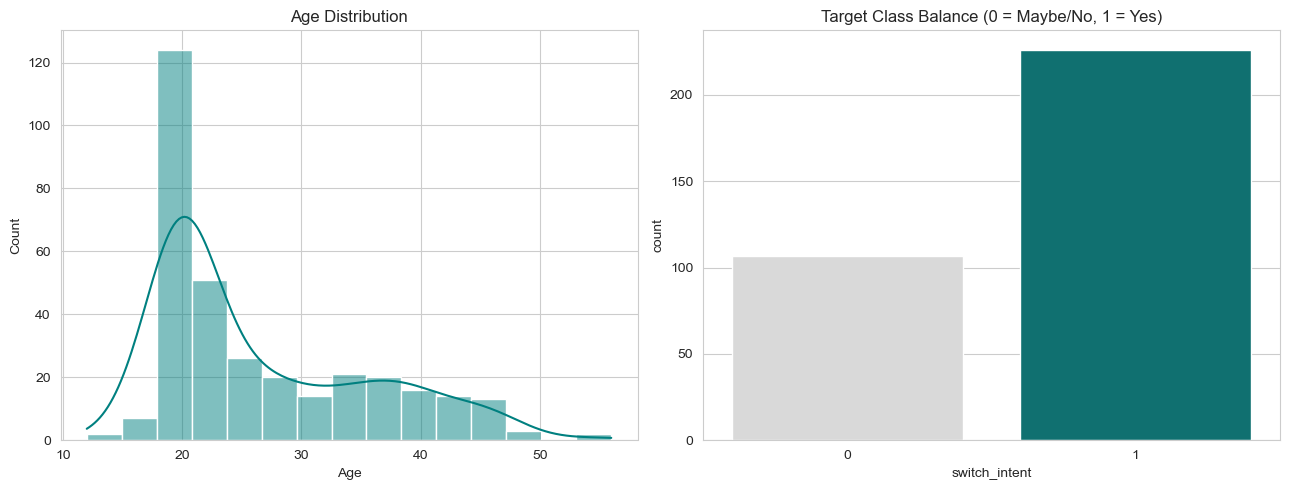

In [120]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df['Age'], bins=15, kde=True, ax=axes[0], color='teal')
axes[0].set_title('Age Distribution')

sns.countplot(x='switch_intent', data=df, ax=axes[1], palette=['#d9d9d9', '#008080'])
axes[1].set_title('Target Class Balance (0 = Maybe/No, 1 = Yes)')

plt.tight_layout()
plt.show()

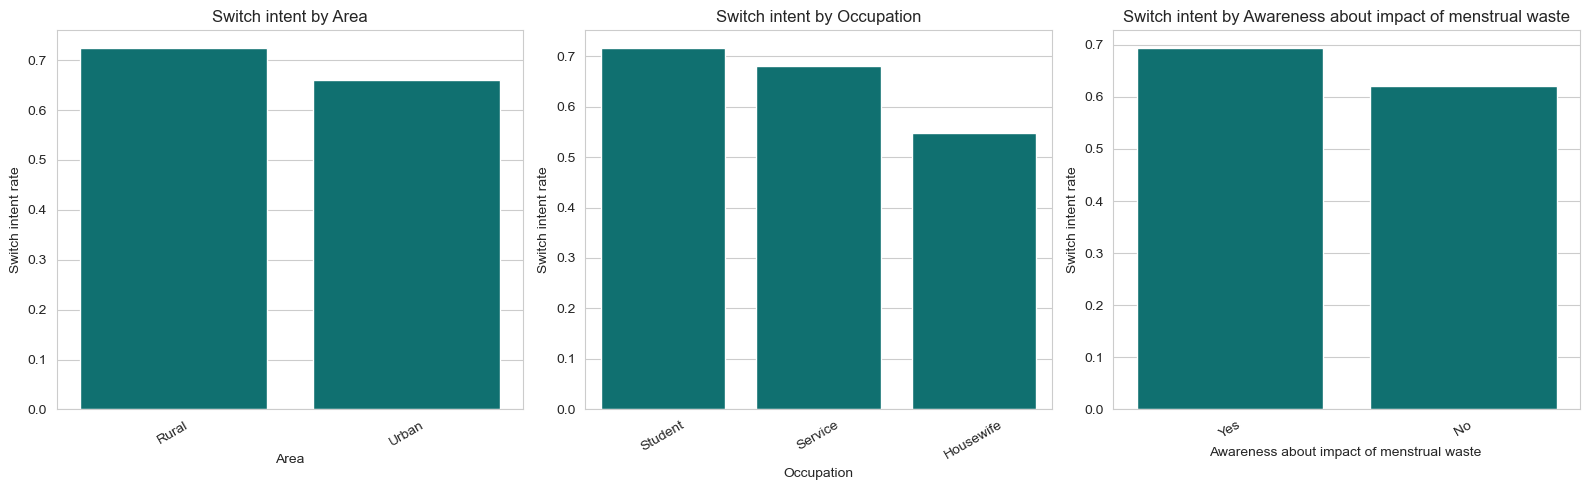

In [121]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, ['Area', 'Occupation', 'Awareness about impact of menstrual waste ']):
    rate = df.groupby(col)['switch_intent'].mean().sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=ax, color='teal')
    ax.set_ylabel('Switch intent rate')
    ax.set_title(f'Switch intent by {col.strip()}')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

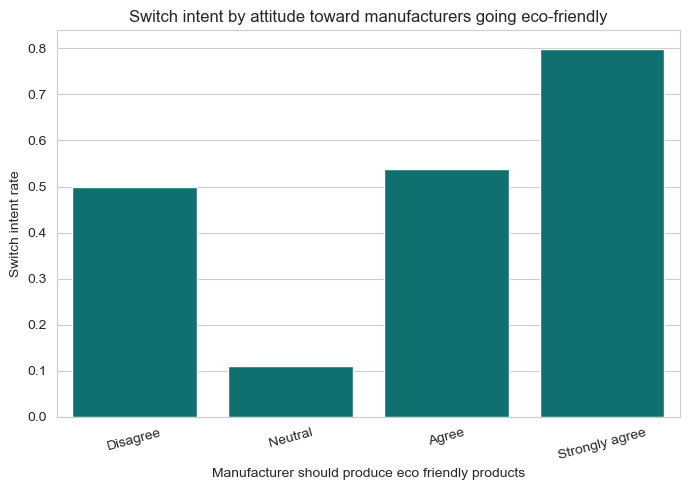

In [122]:
fig, ax = plt.subplots(figsize=(7, 5))
rate = df.groupby('Manufacturer should produce eco friendly products')['switch_intent'].mean()
order = ['Disagree', 'Neutral', 'Agree', 'Strongly agree']
rate = rate.reindex(order)
sns.barplot(x=rate.index, y=rate.values, color='teal', ax=ax)
ax.set_ylabel('Switch intent rate')
ax.set_title('Switch intent by attitude toward manufacturers going eco-friendly')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Observations to note in your presentation:**
- Compare switch-intent rate across urban vs rural respondents and across occupations.
- Awareness of menstrual waste impact is a hypothesized driver of switching intent — check whether the EDA supports this.
- Stronger agreement that manufacturers should produce eco-friendly products tends to track with higher switch intent, which is a good sanity check that the target is behaving sensibly.


## 6. Select Features

Drop the target from the inputs and remove the two long free-text answers. No information is extracted from those answers.

In [123]:
target_column = 'switch_intent'
text_columns = ['Reasons', 'Reason for particular product']

y = df['switch_intent']
X = df.drop(columns=[target_column, *text_columns,'Shift to other product'])

print('Features:', X.shape[1])
print('Target counts:')
print(y.value_counts().sort_index())


Features: 19
Target counts:
switch_intent
0    107
1    226
Name: count, dtype: int64


In [124]:
X.head()

,Age,Occupation,Income,Menstrual product,Area,Intensity of flow,Monthly cost spend,Single day changing frequency,Duration of single product per day,No.of products used for a cycle,Disposable/Reusable product,Method of disposing,Availability of disposable machines,Awareness about impact of menstrual waste,Manufacturer should produce eco friendly products,Promoting Gov policies,Any discomfort,Aware about Gov policies,years_using_product
0,12,Student,50000,Sanitary napkins,Rural,Low,100-150 Rs,Less than 3 times,More than 6 hours,20,Disposable,General household waste,No,Yes,Strongly agree,Yes,No,Yes,3.0
1,14,Student,5000,Organic pads,Urban,Medium,100-150 Rs,Less than 3 times,More than 6 hours,9,Disposable,General household waste,No,Yes,Strongly agree,Yes,Yes,No,2.0
2,15,Student,4000,Sanitary napkins,Urban,Medium,More than 200 Rs,3-5 times,1-3 hours,25,Disposable,General household waste,No,Yes,Agree,Yes,No,Yes,3.0
3,16,Student,50000,Organic pads,Urban,Low,100-150 Rs,Less than 3 times,4-6 hours,9,Disposable,Separated dustbins for sanitary napkins,Yes,Yes,Disagree,Yes,No,Yes,2.0
4,16,Student,8500,Sanitary napkins,Urban,NaN,More than 200 Rs,3-5 times,1-3 hours,20,Disposable,Separated dustbins for sanitary napkins,Yes,No,Strongly agree,Yes,No,No,2.0


## 7. Preprocess Features

Automatically separate numbers from categories. Impute missing values, scale numeric columns, and one-hot encode categories inside the model pipeline.

In [125]:
numeric_features = X.select_dtypes(include='number').columns.tolist()
categorical_features = X.select_dtypes(exclude='number').columns.tolist()

print('Numeric features:', numeric_features)
print('Categorical features:', len(categorical_features))

Numeric features: ['Age', 'Income', 'No.of products used for a cycle', 'years_using_product']
Categorical features: 15


In [126]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features),
])

## 8. Train One Model

Use one stratified 80/20 split and Logistic Regression. The preprocessing is included in the pipeline so training and API predictions apply the same transformations.

In [127]:


# 3. Split, preprocess, and train your model again
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [128]:
X_train_scaled=preprocessor.fit_transform(X_train)
X_test_scaled=preprocessor.transform(X_test)

# 9. Now Build different Base models to compare 


In [136]:
#LogisticRegression

lr=LogisticRegression(class_weight='balanced',max_iter=1000)
lr.fit(X_train_scaled,y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [137]:
#Logistic Tests
y_pred=lr.predict(X_test_scaled)

print("Classification report for Logistic Regression:\n",classification_report(y_pred,y_test))

Classification report for Logistic Regression:
               precision    recall  f1-score   support

           0       0.59      0.45      0.51        29
           1       0.64      0.76      0.70        38

    accuracy                           0.63        67
   macro avg       0.62      0.61      0.60        67
weighted avg       0.62      0.63      0.62        67



The held-out scores are only an initial estimate. Because the survey has 333 responses, a different split may produce different results; collect more responses before using predictions for decisions.

## 9. Check Holdout Results

Review the classification report and confusion matrix on the held-out 20% of rows. With a small dataset, these results can vary between splits and should be treated as a baseline.

              precision    recall  f1-score   support

Maybe/No (0)       0.45      0.59      0.51        22
     Yes (1)       0.76      0.64      0.70        45

    accuracy                           0.63        67
   macro avg       0.61      0.62      0.60        67
weighted avg       0.66      0.63      0.64        67



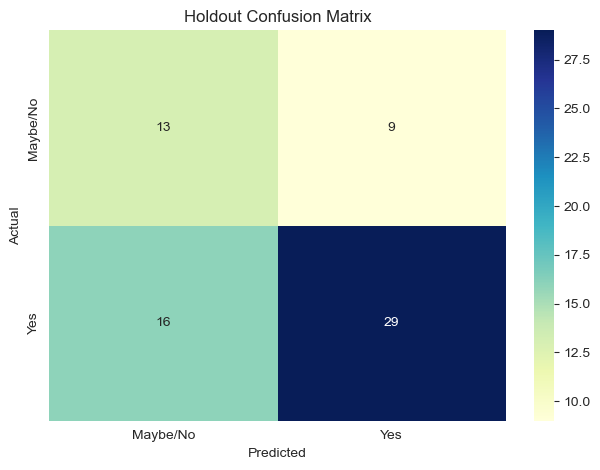

In [138]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['Maybe/No (0)', 'Yes (1)'],
    zero_division=0,
))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    xticklabels=['Maybe/No', 'Yes'],
    yticklabels=['Maybe/No', 'Yes'],
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Holdout Confusion Matrix')
plt.tight_layout()
plt.show()

# Checking Decision Tree Classifier Model

In [142]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# Initialize Random Forest
rf = RandomForestClassifier(n_estimators=200,class_weight='balanced',random_state=42)
# Train using your preprocessed training data
rf.fit(X_train_scaled, y_train)
# Predict and evaluate
y_pred_rf = rf.predict(X_test_scaled)
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.50      0.09      0.15        22
           1       0.68      0.96      0.80        45

    accuracy                           0.67        67
   macro avg       0.59      0.52      0.48        67
weighted avg       0.62      0.67      0.59        67



In [ ]:
#Feature Importances
import pandas as pd

# Get feature names from your preprocessor
feature_names = preprocessor.get_feature_names_out()

# Get feature importances from the trained decision tree
importances = dt.feature_importances_

# Create a dataframe to view the
feature_imp_df = pd.DataFrame(
    {'Feature': feature_names, 'Importance': importances}
)
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False)

print(feature_imp_df.head(10))

# Checking Random Forest Classifier Model

In [146]:

from sklearn.metrics import classification_report

# Initialize Random Forest
dt = DecisionTreeClassifier(max_depth=4,class_weight='balanced',random_state=42)
# Train using your preprocessed training data
dt.fit(X_train_scaled, y_train)
# Predict and evaluate
y_pred_dt = dt.predict(X_test_scaled)
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.47      0.68      0.56        22
           1       0.80      0.62      0.70        45

    accuracy                           0.64        67
   macro avg       0.63      0.65      0.63        67
weighted avg       0.69      0.64      0.65        67



In [150]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Set up 5-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate using Macro F1 (since it accounts for both classes equally)
cv_scores = cross_val_score(
    dt, preprocessor.fit_transform(X), y, cv=cv, scoring='f1_macro'
)

print(f'Cross-Validation Macro F1 Scores: {cv_scores}')
print(f'Average Macro F1: {cv_scores.mean():.2f} (+/- {cv_scores.std():.2f})')

Cross-Validation Macro F1 Scores: [0.49151786 0.5852381  0.630012   0.5875     0.56956522]
Average Macro F1: 0.57 (+/- 0.05)


## After doing all the cross checking the models the best model was Decision Tree which is well generalized on both the classes 
   so we will save this model in pickle file 
   

In [153]:
import joblib
from sklearn.pipeline import Pipeline

# 1. Combine your preprocessor and decision tree into a single pipeline
full_pipeline = Pipeline(
    [('preprocessor', preprocessor), ('classifier', dt)]
)

# 2. Fit the entire pipeline on your raw training data (X_train, y_train)
full_pipeline.fit(X_train, y_train)

# 3. Save the entire pipeline to a file
joblib.dump(full_pipeline, 'eco_menstrual_model_pipeline.pkl')
print('Pipeline saved successfully!')

Pipeline saved successfully!
